# Social Media Toxicity Detection

I use 24,783 annotated Twitter posts and replies (Davidson et al., 2017) to classify toxic language (`hate_speech` and `offensive_language`) against neutral posts (`neither`) using TF-IDF features and Logistic Regression.

In [1]:
import html
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    ConfusionMatrixDisplay,
)

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 140)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 90

In [2]:
comments = pd.read_csv('comments.csv.gz')
print('Rows:', len(comments))
print('Columns:', len(comments.columns))
comments.head()

Rows: 24783
Columns: 7


,post_id,post_text,category,hate_speech_votes,offensive_votes,neither_votes,total_votes
0,0,!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash ou...,neither,0,0,3,3
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!,offensive_language,0,3,0,3
2,2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch and she start to cry? You be confused as shit,offensive_language,0,3,0,3
3,3,!!!!!!!!! RT @C_G_Anderson: @viva_based she look like a tranny,offensive_language,0,2,1,3
4,4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you hear about me might be true or it might be faker than the bitch who told it to ya &#57361;,offensive_language,0,6,0,6


### Target definition and data checks

Each post carries a majority annotation label (`neither`, `offensive_language`, `hate_speech`) and crowd vote counts (`hate_speech_votes`, `offensive_votes`, `neither_votes`, `total_votes`). I combine `offensive_language` and `hate_speech` into a binary target `is_toxic` (1 for Toxic, 0 for Neutral) and record structural post cues (`has_mention`, `is_retweet`, `has_url`) before text cleaning strips handles and links.

In [3]:
comments['is_toxic'] = (comments['category'] != 'neither').astype(int)
comments['label_name'] = comments['is_toxic'].map({0: 'Neutral', 1: 'Toxic'})

comments['char_length'] = comments['post_text'].str.len()
comments['word_count'] = comments['post_text'].str.split().str.len()
comments['has_mention'] = comments['post_text'].str.contains(r'@\w+', regex=True).astype(int)
comments['is_retweet'] = comments['post_text'].str.contains(r'\bRT\b', regex=True).astype(int)
comments['has_url'] = comments['post_text'].str.contains(r'https?://|www\.', regex=True).astype(int)
comments['max_votes'] = comments[['hate_speech_votes', 'offensive_votes', 'neither_votes']].max(axis=1)
comments['unanimous_label'] = comments['max_votes'] == comments['total_votes']

comments.isna().sum()

post_id              0
post_text            0
category             0
hate_speech_votes    0
offensive_votes      0
neither_votes        0
total_votes          0
is_toxic             0
label_name           0
char_length          0
word_count           0
has_mention          0
is_retweet           0
has_url              0
max_votes            0
unanimous_label      0
dtype: int64

### Exploratory Data Analysis

Because the underlying corpus queried Twitter using terms from the Hatebase lexicon, toxic and offensive posts form the majority class while neutral posts (`neither`) make up 16.8% of the sample. Checking both class counts and subcategory totals explains why unweighted classifiers tend to under-recall the neutral minority.

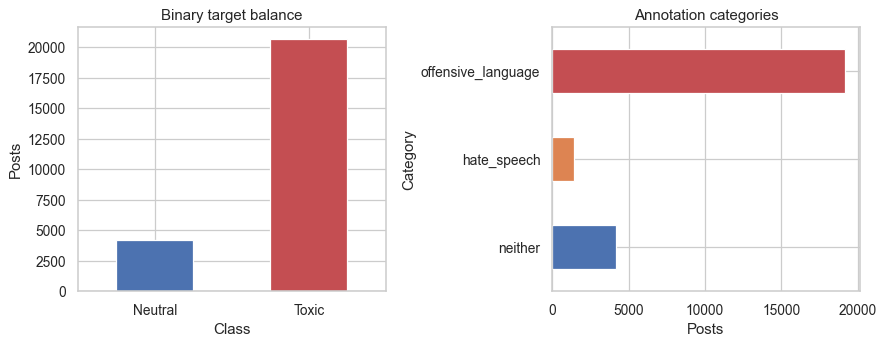

Neutral: 4163 (16.8%)
Toxic: 20620 (83.2%)


In [4]:
class_counts = comments['label_name'].value_counts().reindex(['Neutral', 'Toxic'])
class_shares = comments['label_name'].value_counts(normalize=True).reindex(['Neutral', 'Toxic']) * 100
cat_counts = comments['category'].value_counts().reindex(['neither', 'hate_speech', 'offensive_language'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
class_counts.plot.bar(ax=axes[0], rot=0, color=['#4c72b0', '#c44e52'])
axes[0].set_title('Binary target balance')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Posts')

cat_counts.plot.barh(ax=axes[1], color=['#4c72b0', '#dd8452', '#c44e52'])
axes[1].set_title('Annotation categories')
axes[1].set_xlabel('Posts')
axes[1].set_ylabel('Category')

plt.tight_layout()
plt.show()

for label in ['Neutral', 'Toxic']:
    print(f"{label}: {class_counts[label]} ({class_shares[label]:.1f}%)")

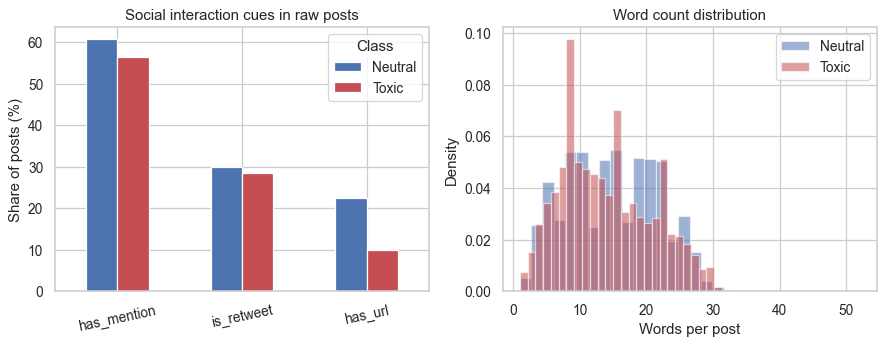

,char_length,word_count,has_mention,is_retweet,has_url,unanimous_label
label_name,,,,,,
Neutral,94.850,14.919,0.607,0.300,0.224,0.690
Toxic,83.535,13.955,0.566,0.286,0.100,0.709


In [5]:
interaction_rates = comments.groupby('label_name')[['has_mention', 'is_retweet', 'has_url']].mean().reindex(['Neutral', 'Toxic'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
(interaction_rates * 100).T.plot.bar(ax=axes[0], rot=12, color=['#4c72b0', '#c44e52'])
axes[0].set_ylabel('Share of posts (%)')
axes[0].set_title('Social interaction cues in raw posts')
axes[0].legend(title='Class')

for label, color in [('Neutral', '#4c72b0'), ('Toxic', '#c44e52')]:
    subset = comments.loc[comments['label_name'] == label, 'word_count']
    axes[1].hist(subset, bins=30, alpha=0.55, density=True, label=label, color=color)
axes[1].set_xlabel('Words per post')
axes[1].set_ylabel('Density')
axes[1].set_title('Word count distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

summary_stats = comments.groupby('label_name')[['char_length', 'word_count', 'has_mention', 'is_retweet', 'has_url', 'unanimous_label']].mean().round(3)
summary_stats

### Text preprocessing and lemmatization

Raw social media posts contain HTML entities (`&amp;`, `&#8220;`), `RT` prefixes, `@mentions`, shortened links, contractions, and inflected forms. Before vectorizing text, I decode HTML entities, expand contractions, strip URLs, handles, ordinals, and punctuation, drop standard stopwords while retaining negation words (`not`, `no`, `nor`, `never`), and reduce inflected tokens to base forms.

In [6]:
CONTRACTIONS = [
    (r"\bwhat's\b", 'what is'),
    (r"\bit's\b", 'it is'),
    (r"\bthat's\b", 'that is'),
    (r"\bthere's\b", 'there is'),
    (r"\bi'm\b", 'i am'),
    (r"\byou're\b", 'you are'),
    (r"\bthey're\b", 'they are'),
    (r"\bwe're\b", 'we are'),
    (r"\bdon't\b", 'do not'),
    (r"\bdoesn't\b", 'does not'),
    (r"\bdidn't\b", 'did not'),
    (r"\bcan't\b", 'can not'),
    (r"\bwon't\b", 'will not'),
    (r"\bain't\b", 'is not'),
    (r"\by'all\b", 'you all'),
    (r"n't\b", ' not'),
    (r"'re\b", ' are'),
    (r"'ve\b", ' have'),
    (r"'ll\b", ' will'),
    (r"'d\b", ' would'),
    (r"'m\b", ' am'),
    (r"'s\b", ''),
]

# Retaining negation words prevents flipping the meaning of neutral vs toxic phrases.
NEGATIONS = {'not', 'no', 'nor', 'never'}
STOPWORDS = ENGLISH_STOP_WORDS - NEGATIONS

IRREGULAR_LEMMAS = {
    'men': 'man', 'women': 'woman', 'children': 'child', 'people': 'person',
    'better': 'good', 'best': 'good', 'worse': 'bad', 'worst': 'bad',
    'making': 'make', 'made': 'make', 'taking': 'take', 'took': 'take',
    'giving': 'give', 'gave': 'give', 'coming': 'come', 'came': 'come',
    'going': 'go', 'went': 'go', 'having': 'have', 'had': 'have',
    'being': 'be', 'was': 'be', 'were': 'be', 'doing': 'do', 'done': 'do',
    'said': 'say', 'told': 'tell', 'got': 'get', 'ran': 'run',
    'written': 'write', 'wrote': 'write', 'lying': 'lie', 'dying': 'die',
    'bitches': 'bitch', 'asses': 'ass', 'hoes': 'hoe', 'guys': 'guy',
    'brownies': 'brownie', 'movies': 'movie', 'cookies': 'cookie', 'yankees': 'yankee',
    'niggas': 'nigga', 'niggah': 'nigga', 'faggots': 'faggot',
}

KEEP_ENDING = {'bed', 'red', 'fed', 'led', 'need', 'feed', 'king', 'ring', 'sing', 'thing', 'bring', 'during', 'nothing', 'morning', 'fucking'}


def lemmatize_token(token):
    if token in IRREGULAR_LEMMAS:
        return IRREGULAR_LEMMAS[token]
    if len(token) <= 3 or token in KEEP_ENDING:
        return token
    if token.endswith('ies') and len(token) > 4:
        return token[:-3] + 'y'
    if token.endswith(('ches', 'shes', 'sses', 'xes', 'zzes')) and len(token) > 4:
        return token[:-2]
    if token.endswith('s') and not token.endswith(('ss', 'us', 'is', 'ness', 'less', 'as')):
        return token[:-1]
    if token.endswith(('ing', 'ed')):
        suffix_len = 3 if token.endswith('ing') else 2
        if len(token) - suffix_len < 2:
            return token
        if token.endswith('ied') and len(token) > 4:
            return token[:-3] + 'y'
        stem = token[:-suffix_len]
        if len(stem) >= 2 and stem[-1] == stem[-2] and stem[-1] not in 'lsz':
            return stem[:-1]
        if (
            stem.endswith(('iz', 'dg', 'c', 'v', 'us')) and stem != 'focus'
            or (len(stem) >= 3 and stem[-1] not in 'aeiouwxyhlmnrstp' and stem[-2] in 'aeiou' and stem[-3] not in 'aeiou')
        ):
            return stem + 'e'
        return stem
    return token


def clean_and_lemmatize(text):
    text = html.unescape(str(text)).lower()
    for pattern, replacement in CONTRACTIONS:
        text = re.sub(pattern, replacement, text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'\brt\b', ' ', text)
    text = re.sub(r'\b\d+(?:st|nd|rd|th)\b', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [
        lemmatize_token(tok)
        for tok in text.split()
        if len(tok) > 1 and tok not in STOPWORDS
    ]
    return ' '.join(tokens)

In [7]:
comments['clean_text'] = comments['post_text'].apply(clean_and_lemmatize)

rows_before = len(comments)
comments = comments.loc[comments['clean_text'].str.len() > 0].copy()
comments = comments.drop_duplicates(subset='clean_text').reset_index(drop=True)
print('Rows removed (empty or duplicate after cleaning):', rows_before - len(comments))
print('Rows retained:', len(comments))

comments[['category', 'label_name', 'post_text', 'clean_text']].head(6)

Rows removed (empty or duplicate after cleaning): 1239
Rows retained: 23544


,category,label_name,post_text,clean_text
0,neither,Neutral,!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash ou...,woman not complain clean house man trash
1,offensive_language,Toxic,!!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!,boy dat cold tyga dwn bad cuffin dat hoe place
2,offensive_language,Toxic,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch and she start to cry? You be confused as shit,dawg fuck bitch start confuse shit
3,offensive_language,Toxic,!!!!!!!!! RT @C_G_Anderson: @viva_based she look like a tranny,look like tranny
4,offensive_language,Toxic,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you hear about me might be true or it might be faker than the bitch who told it to ya &#57361;,shit hear true faker bitch tell ya
5,offensive_language,Toxic,"!!!!!!!!!!!!!!!!!!""@T_Madison_x: The shit just blows me..claim you so faithful and down for somebody but still fucking with hoes! &#1285...",shit just blow claim faithful somebody fucking hoe


### Train, cross-validation and test sets

I hold out 20% of cleaned posts as a stratified test split and run 5-fold stratified cross-validation on the remaining 80% for model selection.

In [8]:
X = comments['clean_text']
y = comments['is_toxic']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Training posts: {len(X_train)} (toxic rate: {y_train.mean():.3f})")
print(f"Test posts: {len(X_test)} (toxic rate: {y_test.mean():.3f})")

Training posts: 18835 (toxic rate: 0.829)
Test posts: 4709 (toxic rate: 0.829)


### Baseline TF-IDF and Logistic Regression

As a baseline, I vectorize posts using unigram TF-IDF features (`max_features=15000`, `min_df=3`) and train an unweighted `LogisticRegression` classifier (`C=1.0`).

In [9]:
baseline_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 1), max_features=15000, min_df=3),
    LogisticRegression(C=1.0, max_iter=1000, random_state=42),
)

baseline_cv_macro_f1 = cross_val_score(baseline_model, X_train, y_train, cv=cv, scoring='f1_macro')
baseline_cv_auc = cross_val_score(baseline_model, X_train, y_train, cv=cv, scoring='roc_auc')

baseline_model.fit(X_train, y_train)
baseline_test_pred = baseline_model.predict(X_test)
baseline_test_proba = baseline_model.predict_proba(X_test)[:, 1]

print(f"Baseline CV Macro F1: {baseline_cv_macro_f1.mean():.3f} (+/- {baseline_cv_macro_f1.std():.3f})")
print(f"Baseline CV ROC-AUC: {baseline_cv_auc.mean():.3f} (+/- {baseline_cv_auc.std():.3f})")
print(f"Baseline Test Accuracy: {accuracy_score(y_test, baseline_test_pred):.3f}")
print(classification_report(y_test, baseline_test_pred, target_names=['Neutral', 'Toxic'], digits=3))

Baseline CV Macro F1: 0.897 (+/- 0.005)
Baseline CV ROC-AUC: 0.980 (+/- 0.001)
Baseline Test Accuracy: 0.948
              precision    recall  f1-score   support

     Neutral      0.883     0.804     0.842       807
       Toxic      0.960     0.978     0.969      3902

    accuracy                          0.948      4709
   macro avg      0.922     0.891     0.905      4709
weighted avg      0.947     0.948     0.947      4709



### Tuned regularized Logistic Regression

Because the unweighted baseline under-predicts the minority `Neutral` class, I add bigrams (`ngram_range=(1, 2)`), apply sublinear TF scaling (`sublinear_tf=True`), and tune L2 regularization `C` together with `class_weight` using 5-fold cross-validation scored on `f1_macro` so both neutral and toxic classes remain balanced.

In [10]:
tuned_pipeline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=3, sublinear_tf=True),
    LogisticRegression(max_iter=1000, random_state=42),
)

param_grid = {
    'logisticregression__C': [0.5, 1.0, 2.0, 4.0],
    'logisticregression__class_weight': [None, {0: 2, 1: 1}, {0: 3, 1: 1}, 'balanced'],
}

grid_search = GridSearchCV(
    tuned_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=1,
)
grid_search.fit(X_train, y_train)

cv_summary = (
    pd.DataFrame(grid_search.cv_results_)[
        ['param_logisticregression__C', 'param_logisticregression__class_weight', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ]
    .rename(columns={
        'param_logisticregression__C': 'C',
        'param_logisticregression__class_weight': 'class_weight',
        'mean_test_score': 'CV Macro F1',
        'std_test_score': 'CV F1 std',
        'rank_test_score': 'Rank',
    })
    .sort_values('Rank')
)
print('Best parameters:', grid_search.best_params_)
print(f"Best CV Macro F1: {grid_search.best_score_:.3f}")
cv_summary.head(10).round(4)

Best parameters: {'logisticregression__C': 2.0, 'logisticregression__class_weight': {0: 3, 1: 1}}
Best CV Macro F1: 0.919


,C,class_weight,CV Macro F1,CV F1 std,Rank
10,2.0,"{0: 3, 1: 1}",0.9191,0.0012,1
13,4.0,"{0: 2, 1: 1}",0.9188,0.0020,2
9,2.0,"{0: 2, 1: 1}",0.9187,0.0029,3
14,4.0,"{0: 3, 1: 1}",0.9181,0.0021,4
5,1.0,"{0: 2, 1: 1}",0.9178,0.0017,5
6,1.0,"{0: 3, 1: 1}",0.9168,0.0055,6
2,0.5,"{0: 3, 1: 1}",0.9144,0.0060,7
15,4.0,balanced,0.9130,0.0024,8
1,0.5,"{0: 2, 1: 1}",0.9106,0.0019,9
11,2.0,balanced,0.9101,0.0044,10


In [11]:
best_model = grid_search.best_estimator_
tuned_cv_auc = cross_val_score(best_model, X_train, y_train, cv=cv, scoring='roc_auc')

tuned_test_pred = best_model.predict(X_test)
tuned_test_proba = best_model.predict_proba(X_test)[:, 1]

print(f"Tuned CV ROC-AUC: {tuned_cv_auc.mean():.3f} (+/- {tuned_cv_auc.std():.3f})")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_test_pred):.3f}")
print(f"Test Macro F1: {f1_score(y_test, tuned_test_pred, average='macro'):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, tuned_test_proba):.3f}")
print(classification_report(y_test, tuned_test_pred, target_names=['Neutral', 'Toxic'], digits=3))

Tuned CV ROC-AUC: 0.981 (+/- 0.001)
Test Accuracy: 0.955
Test Macro F1: 0.924
Test ROC-AUC: 0.983
              precision    recall  f1-score   support

     Neutral      0.827     0.932     0.876       807
       Toxic      0.986     0.960     0.972      3902

    accuracy                          0.955      4709
   macro avg      0.906     0.946     0.924      4709
weighted avg      0.958     0.955     0.956      4709



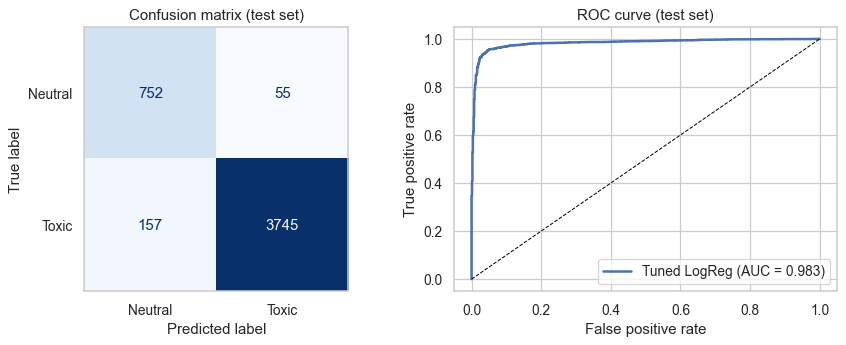

In [12]:
fpr, tpr, _ = roc_curve(y_test, tuned_test_proba)
test_auc = roc_auc_score(y_test, tuned_test_proba)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_test_pred, display_labels=['Neutral', 'Toxic'], cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].grid(False)
axes[0].set_title('Confusion matrix (test set)')

axes[1].plot(fpr, tpr, color='#4c72b0', linewidth=2, label=f'Tuned LogReg (AUC = {test_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=0.8)
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve (test set)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Performance across speech markers and annotator consensus

Next, I check test recall across the three original label categories (`neither`, `offensive_language`, `hate_speech`) and compare posts with unanimous crowd agreement against split-vote cases.

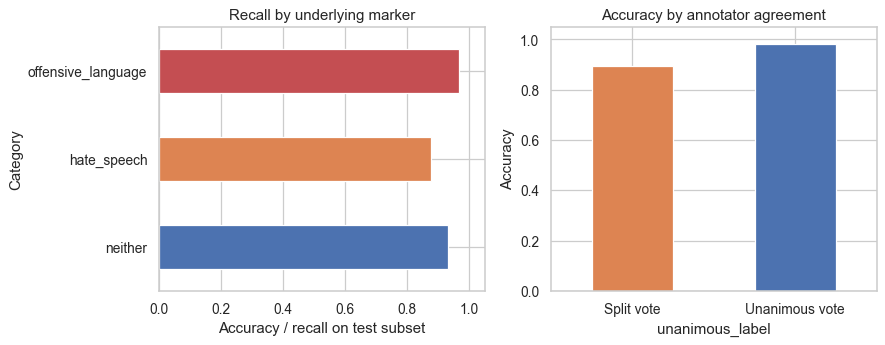

,Test posts,Class recall
Category,,
neither,807,0.932
hate_speech,295,0.878
offensive_language,3607,0.966


In [13]:
test_meta = comments.loc[X_test.index].copy()
test_meta['y_true'] = y_test.values
test_meta['y_pred'] = tuned_test_pred
test_meta['correct'] = (test_meta['y_true'] == test_meta['y_pred']).astype(int)

cat_rows = []
for cat in ['neither', 'hate_speech', 'offensive_language']:
    sub = test_meta[test_meta['category'] == cat]
    cat_rows.append({
        'Category': cat,
        'Test posts': len(sub),
        'Class recall': sub['correct'].mean(),
    })

cat_eval = pd.DataFrame(cat_rows).set_index('Category')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cat_eval['Class recall'].plot.barh(ax=axes[0], color=['#4c72b0', '#dd8452', '#c44e52'])
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel('Accuracy / recall on test subset')
axes[0].set_title('Recall by underlying marker')

consensus_acc = test_meta.groupby('unanimous_label')['correct'].mean().rename(index={False: 'Split vote', True: 'Unanimous vote'})
consensus_acc.plot.bar(ax=axes[1], rot=0, color=['#dd8452', '#4c72b0'])
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy by annotator agreement')

plt.tight_layout()
plt.show()

cat_eval.round(3)

### TF-IDF feature coefficients

Positive Logistic Regression weights increase the log-odds of `Toxic` (`offensive_language` or `hate_speech`), while negative weights push predictions toward `Neutral` (`neither`).

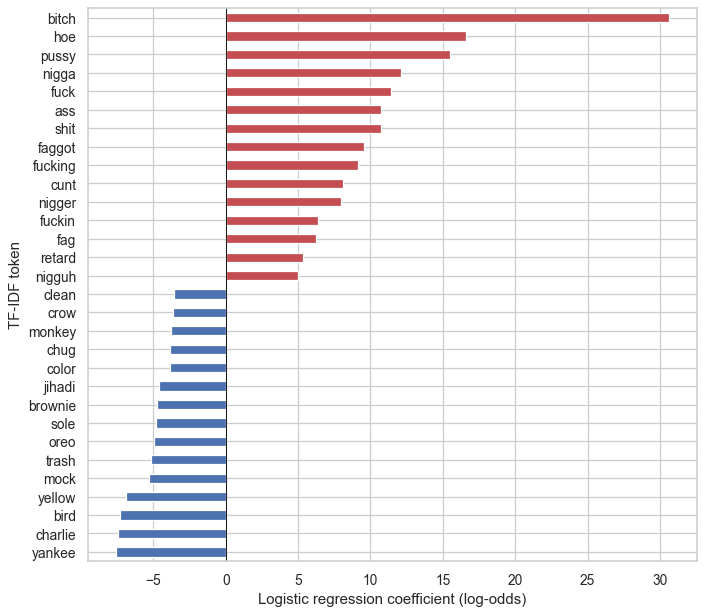

,Top Neutral tokens,Neutral weight,Top Toxic tokens,Toxic weight
0,yankee,-7.599,bitch,30.626
1,charlie,-7.443,hoe,16.610
2,bird,-7.339,pussy,15.518
3,yellow,-6.917,nigga,12.129
4,mock,-5.335,fuck,11.430
5,trash,-5.145,ass,10.748
6,oreo,-4.964,shit,10.718
7,sole,-4.830,faggot,9.535
8,brownie,-4.750,fucking,9.152
9,jihadi,-4.589,cunt,8.096


In [14]:
vec = best_model.named_steps['tfidfvectorizer']
clf = best_model.named_steps['logisticregression']
feature_weights = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())

top_features = pd.concat([feature_weights.nsmallest(15), feature_weights.nlargest(15)]).sort_values()

plt.figure(figsize=(8, 7))
colors = ['#4c72b0' if v < 0 else '#c44e52' for v in top_features.values]
top_features.plot.barh(color=colors)
plt.axvline(0, color='black', linewidth=0.7)
plt.xlabel('Logistic regression coefficient (log-odds)')
plt.ylabel('TF-IDF token')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'Top Neutral tokens': feature_weights.nsmallest(10).index,
    'Neutral weight': feature_weights.nsmallest(10).values.round(3),
    'Top Toxic tokens': feature_weights.nlargest(10).index,
    'Toxic weight': feature_weights.nlargest(10).values.round(3),
})

Notice that while positive coefficients align directly with profanity and slurs, strongly negative (`Neutral`) coefficients include nouns such as `yankee`, `bird`, `charlie`, `brownie`, and `trash`. Because the corpus queried Twitter using ambiguous Hatebase seed terms, benign sports, food, and news posts containing those keywords form a large fraction of the `neither` class.

### Model comparison

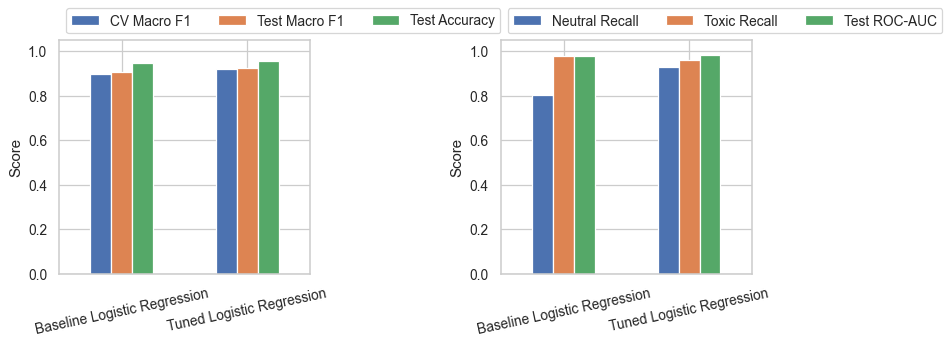

,CV Macro F1,CV ROC-AUC,Test Accuracy,Neutral Recall,Toxic Recall,Test Macro F1,Test ROC-AUC
Baseline Logistic Regression,0.897,0.980,0.948,0.804,0.978,0.905,0.981
Tuned Logistic Regression,0.919,0.981,0.955,0.932,0.960,0.924,0.983


In [15]:
results = pd.DataFrame({
    'CV Macro F1': [baseline_cv_macro_f1.mean(), grid_search.best_score_],
    'CV ROC-AUC': [baseline_cv_auc.mean(), tuned_cv_auc.mean()],
    'Test Accuracy': [
        accuracy_score(y_test, baseline_test_pred),
        accuracy_score(y_test, tuned_test_pred),
    ],
    'Neutral Recall': [
        recall_score(y_test, baseline_test_pred, pos_label=0),
        recall_score(y_test, tuned_test_pred, pos_label=0),
    ],
    'Toxic Recall': [
        recall_score(y_test, baseline_test_pred, pos_label=1),
        recall_score(y_test, tuned_test_pred, pos_label=1),
    ],
    'Test Macro F1': [
        f1_score(y_test, baseline_test_pred, average='macro'),
        f1_score(y_test, tuned_test_pred, average='macro'),
    ],
    'Test ROC-AUC': [
        roc_auc_score(y_test, baseline_test_proba),
        roc_auc_score(y_test, tuned_test_proba),
    ],
}, index=['Baseline Logistic Regression', 'Tuned Logistic Regression'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
results[['CV Macro F1', 'Test Macro F1', 'Test Accuracy']].plot.bar(ax=axes[0], rot=12)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel('Score')
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3)

results[['Neutral Recall', 'Toxic Recall', 'Test ROC-AUC']].plot.bar(ax=axes[1], rot=12)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Score')
axes[1].legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3)

plt.tight_layout()
plt.show()

results.round(3)

### Error analysis

To see where an isolated TF-IDF model fails, I inspect high-confidence false positives and false negatives from the test split.

In [16]:
error_df = pd.DataFrame({
    'category': comments.loc[X_test.index, 'category'],
    'true_label': y_test.map({0: 'Neutral', 1: 'Toxic'}),
    'pred_label': pd.Series(tuned_test_pred, index=y_test.index).map({0: 'Neutral', 1: 'Toxic'}),
    'toxic_prob': np.round(tuned_test_proba, 3),
    'post_text': comments.loc[X_test.index, 'post_text'],
})

false_positives = error_df[(error_df['true_label'] == 'Neutral') & (error_df['pred_label'] == 'Toxic')]
false_negatives = error_df[(error_df['true_label'] == 'Toxic') & (error_df['pred_label'] == 'Neutral')]

print('False positives:', len(false_positives))
print('False negatives:', len(false_negatives))

error_examples = pd.concat([
    false_positives.sort_values('toxic_prob', ascending=False).head(5),
    false_negatives.sort_values('toxic_prob', ascending=True).head(5),
])
error_examples[['category', 'true_label', 'pred_label', 'toxic_prob', 'post_text']]

False positives: 55
False negatives: 157


,category,true_label,pred_label,toxic_prob,post_text
18229,neither,Neutral,Toxic,0.991,RT @iDntWearCondoms: If u acted like a hoe after we broke up I'm not wrong for thinking u were a hoe all along
8134,neither,Neutral,Toxic,0.987,Dallas hoe RT @beanreturns: Why http://t.co/D6HAlItFmP
18683,neither,Neutral,Toxic,0.977,RT @maycie32: @Whitecholo23 np big nig nig
12305,neither,Neutral,Toxic,0.967,Money hungry hoes they can never get a crumb
14856,neither,Neutral,Toxic,0.965,RT @HoskinsTy96: @Vontey_isa_boss &#128514;&#128514;&#128514; ghetto ass mofos
8058,offensive_language,Toxic,Neutral,0.004,Corey is trash
16499,offensive_language,Toxic,Neutral,0.007,RT @Shawnzie3: Foxtrot\nUniform\nCharlie\nKilo.
12144,offensive_language,Toxic,Neutral,0.008,Man I'm tryin to take my intoxication to Charlie Sheen levels today and I'm going to do just that
3482,offensive_language,Toxic,Neutral,0.024,@JaredReve use monkey maker you prick!
21162,offensive_language,Toxic,Neutral,0.034,"Trash.. see how i capitalized the ""T"" in Trash.. RT @misskai__: Wtf is this Oreo song by r Kelly ? &#128514; tf"


### Limitations and next steps

The tuned bigram Logistic Regression improves test Macro F1 from 0.905 to 0.924 over the unweighted baseline and raises Neutral recall from 0.804 to 0.932 while keeping Toxic recall at 0.960 (accuracy 0.955, ROC-AUC 0.983). Across the original categories, recall reaches 0.966 on `offensive_language`, 0.932 on `neither`, and 0.878 on `hate_speech`.

Inspecting the test errors (55 false positives and 157 false negatives) shows two clear limits of classifying posts from isolated word n-grams. First, word weights struggle when toxic posts avoid direct profanity (such as `"Foxtrot Uniform Charlie Kilo"`), when Hatebase seed nouns (`trash`, `charlie`, `oreo`, `monkey`) push log-odds toward Neutral, or when annotator labels disagree on slang terms. Second, although 60.7% of neutral posts and 56.6% of toxic posts include `@mentions` (and 30.0% vs 28.6% are retweets), preprocessing drops handles and this snapshot has no thread IDs or timestamps. Studying communication flows between users who post toxic content and tracking how they interact further would require reply-graph data across conversation threads.